# I этап — установка библиотек (если не установлены)

In [1]:
# используем "тихий" режим "--quiet", чтобы не засорять тут ячейки

%pip install geopandas matplotlib numpy pandas shapely --quiet

Note: you may need to restart the kernel to use updated packages.


# II этап — импорт библиотек и модулей

In [2]:
import sqlite3
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Circle
from shapely.geometry import Point

# III этап — cоздание тестовой базы данных в памяти

In [3]:
con = sqlite3.connect(":memory:")

con.executescript("""
CREATE TABLE stations (
  station TEXT PRIMARY KEY,
  x REAL NOT NULL,
  y REAL NOT NULL
);

CREATE TABLE measurements (
  station TEXT NOT NULL,
  value REAL NOT NULL
);
""")

con.executemany(
    "INSERT INTO stations VALUES (?, ?, ?)",
    [("A", 0, 0), ("B", 3, 0), ("C", 0, 4), ("D", 6, 8)],
)
con.executemany(
    "INSERT INTO measurements VALUES (?, ?)",
    [
        ("A", 10), ("A", 14),
        ("B", 8),  ("B", 12),
        ("C", 16), ("C", 20),
        ("D", 22), ("D", 26),
    ],
);

# IV этап — TODO 1: SQL-запрос для получения данных

In [4]:
# соединяем таблицы stations и measurements по полю station и выбираем столбцы: station, x, y, value

data = pd.read_sql_query("""
    SELECT s.station, s.x, s.y, m.value
    FROM stations AS s
    JOIN measurements AS m ON s.station = m.station
""", con)

# V этап — TODO 2: рассчёт среднего значения для каждой станции

In [5]:
# группируем по station, x, y и вычисляем среднее по value;
# переименовываем столбец value в mean_value

summary = (
    data.groupby(["station", "x", "y"], as_index=False)["value"]
        .mean()
        .rename(columns={"value": "mean_value"})
)

# VI этап — TODO 3: создание GeoDataFrame и вычисление расстояний

In [6]:
## 3.1: создаём GeoDataFrame из summary, используя координаты x и y

points = gpd.GeoDataFrame(
    summary,
    geometry=gpd.points_from_xy(summary["x"], summary["y"])
)

In [7]:
# 3.2: вычисляем расстояние от каждой точки до центра (0, 0); 
#      сохраняем результат в столбец distance_km

points["distance_km"] = points.geometry.distance(Point(0, 0))

# VII этап — TODO 4: отбор пунктов по двум условиям

In [8]:
# условие 1: расстояние <= 5 км;
# условие 2: среднее значение >= 12;
# cохраняем результат в столбец selected (True/False)

points["selected"] = (
    (points["distance_km"] <= 5) & (points["mean_value"] >= 12)
)

# VIII этап — TODO 5: вычисление итогового среднего по отобранным пунктам

In [9]:
# используем NumPy для расчёта

selected_values = points.loc[
    points["selected"], "mean_value"
]
result = np.mean(selected_values)

## Вывод результатов:

In [10]:
print(points[["station", "mean_value", "distance_km", "selected"]].to_string(index=False))
print(f"Среднее среди выбранных пунктов: {result:.1f}")

station  mean_value  distance_km  selected
      A        12.0          0.0      True
      B        10.0          3.0     False
      C        18.0          4.0      True
      D        24.0         10.0     False
Среднее среди выбранных пунктов: 15.0


# IX этап — ФИНАЛЬНЫЙ — TODO 6: построение визуализации

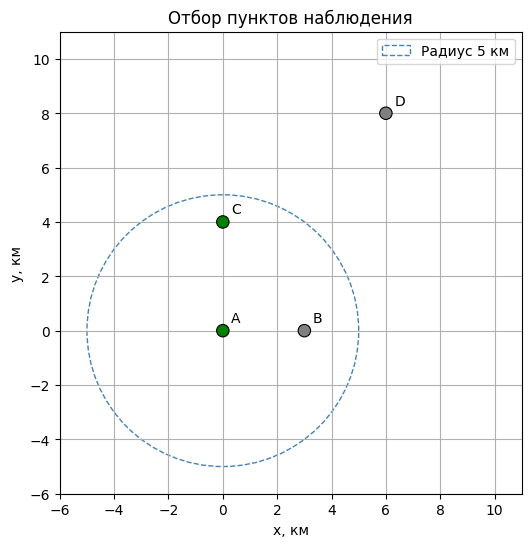

In [11]:
fig, ax = plt.subplots(figsize=(6, 6))

# добавляем круг радиусом 5 км
ax.add_patch(Circle((0, 0), 5, fill=False, linestyle="--",
                    color="steelblue", label="Радиус 5 км"))

# 6.1: создаём массив цветов: "green" для выбранных, "gray" для остальных
colors = np.where(
    points["selected"], "green", "gray"
)

# 6.2: строим scatter-график точек
ax.scatter(
    points["x"], points["y"], c=colors, s=80,
    edgecolors="black", linewidths=0.8, zorder=3
)

# добавляем подписи станций
for row in points.itertuples():
    ax.annotate(row.station, (row.x, row.y), xytext=(6, 6),
                textcoords="offset points")

ax.set(xlabel="x, км", ylabel="y, км", title="Отбор пунктов наблюдения")
ax.set_aspect("equal")
ax.set_xlim(-6, 11)
ax.set_ylim(-6, 11)
ax.grid(True)
ax.legend()
plt.show()

con.close()